In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import keras
import tensorflow as tf
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import MinMaxScaler

In [3]:
df1 = pd.read_csv(r"/content/Google_Stock_Price_Train.csv")
df2 = pd.read_csv(r"/content/Google_Stock_Price_Test.csv")

In [4]:
df1.shape,df2.shape

((1258, 6), (20, 6))

In [5]:
train = df1[['High']]
train.head()

,High
0,332.83
1,333.87
2,330.75
3,328.77
4,322.29


In [6]:
test = df2[['High']]
test.head()

,High
0,789.63
1,791.34
2,794.48
3,807.90
4,809.97


In [7]:
min_max = MinMaxScaler()
train1 = min_max.fit_transform(train)

In [8]:
train1

array([[0.09640129],
       [0.09834351],
       [0.09251685],
       ...,
       [0.95807422],
       [0.94257381],
       [0.93669113]], shape=(1258, 1))

In [9]:
#### Window size = 60
x_train = []
y_train = []
for i in range(60,len(train1)):
  x_train.append(train1[i-60:i,0])
  y_train.append(train1[i,0])
x_train= np.array(x_train)
y_train= np.array(y_train)

* Here we need to prepare the data like sets our window size will be 60.
* So First time i value is 60. So and next step we are given i-60 So 60-60=0.
* For 1st set it will take from 0 to 59 as x_train data.
* So in y_train we are given i value i.e 60. Now 60th row value will be y_train.
* like that for next time i will become 61. So 61-60 is 1. From 1 to 60th column will be our x_train. and i value is 61. So i train value will be 61th rows index value.
* For next step i value becomes 62. 62-60 so from index 2 to index61 will be training data and 62 index will be y_train data like that it do the process and create the training sets for model.

In [10]:
x_train.shape,y_train.shape

((1198, 60), (1198,))

* 1198 are the no.of data sets prepared and if do the Total data-window size we will get our window size i.e 1258-1198=60

In [11]:
x_train = x_train.reshape(x_train.shape[0],x_train.shape[1],1)
x_train.shape

(1198, 60, 1)

In [12]:
x_train.ndim

3

* Here we are using the time step measn conversion of 2D to 3D bcs the we need to pass one-one data to the model if we dircetly into 2D format the model will be looking like ANN.

### RNN (Recurent Neural Network)

In [13]:
## Model Buliding
## Input layer and First Hidden layer
rnn = tf.keras.models.Sequential()
rnn.add(tf.keras.layers.SimpleRNN(units=60,return_sequences=True,input_shape=(60,1)))
### Scond Hidden layer
rnn.add(tf.keras.layers.SimpleRNN(units=60,return_sequences=True))
### Third Hidden layer
rnn.add(tf.keras.layers.SimpleRNN(units=60,return_sequences=True))
## Fourth Hidden layer
rnn.add(tf.keras.layers.SimpleRNN(units=60))
### Output Layer
rnn.add(tf.keras.layers.Dense(units=1))

* Here units=60 # Is the No.of Hidden Neurons we wants in the Hidden_layer.
* Next given return_sequences=True #imp to give. If give True than only the Step-Operation will happen.
* Step-Operation :- Consider the Hidden layer-1. first neuron this neuron will recive inputs from all the neurons present in input layer one by one do the calculation and from this neuron than only next input will be passed. This process will happen in 3D.
* in Fourth layer we are not-given returen_sequnces=True bcs if we give true the process will happen in 3D way and the output will be in the 3D way to avoid that we not given return sequcne=True.
* "Input_shape=60,1"
means our 60 is window size and our time step is 1 so given 1.

In [30]:
### Model Compile
rnn.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),loss=tf.keras.losses.mse)

In [31]:
## Model Training
rnn.fit(x_train,y_train,epochs=30,batch_size=40)

Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - loss: 0.0461
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0052
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 0.0015
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 8.4554e-04
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 7.4442e-04
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 6.9556e-04
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - loss: 7.8281e-04
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - loss: 8.8287e-04
Epoch 9/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - loss: 7.1771e-04
Epoch 10/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - loss: 7.4235e-04
Epoch 11/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 9.4030e-04
Epoch 12/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - loss: 7.2078e-04
Epoch 13/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - loss: 5.4036e-04
Epoch 14/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step - loss: 9.2860e-04
Epoch 15/30
30/30 ━━━━━━━━

In [32]:
test.head()

,High
0,789.63
1,791.34
2,794.48
3,807.90
4,809.97


In [33]:
data = pd.concat([train,test])
data.head()

,High
0,332.83
1,333.87
2,330.75
3,328.77
4,322.29


In [34]:
data.shape

(1278, 1)

In [35]:
data1 = data[len(data)-len(test)-60:]
data1.head()

,High
1198,780.48
1199,779.66
1200,789.38
1201,792.28
1202,788.13


In [36]:
data1.shape

(80, 1)

* For x_test and y_test data prepartion we are combining the train and test data.
* but our test size is 20 and window size is 60.
* 60+20=80 here to prepare the data in set format we only need last 80 rows so to do that we used the above method from original data we are subtracting test data and window size so that will give us the required 80 rows for test data prepartion.

In [37]:
data1 = min_max.transform(data1)
data1

array([[0.93239584],
       [0.93086447],
       [0.94901675],
       [0.95443255],
       [0.94668235],
       [0.9337778 ],
       [0.93887613],
       [0.94242441],
       [0.9718565 ],
       [0.97744038],
       [0.97626384],
       [0.96791604],
       [0.99719872],
       [1.        ],
       [0.98188507],
       [0.97536743],
       [0.99777765],
       [0.96298579],
       [0.94922218],
       [0.93458084],
       [0.91273087],
       [0.91349655],
       [0.94119185],
       [0.96068874],
       [0.95247166],
       [0.95235961],
       [0.89560573],
       [0.8901339 ],
       [0.9024035 ],
       [0.90602648],
       [0.91786655],
       [0.92216184],
       [0.91226399],
       [0.92582217],
       [0.90961212],
       [0.90348666],
       [0.9306217 ],
       [0.92869815],
       [0.91840813],
       [0.89386894],
       [0.88294396],
       [0.90143239],
       [0.91063925],
       [0.91536407],
       [0.92810055],
       [0.94911013],
       [0.95250901],
       [0.977

In [38]:
### Testing data preparation
x_test= []
for i in range(60,len(data1)):
  x_test.append(data1[i-60:i,0])
x_test = np.array(x_test)
x_test = x_test.reshape(x_test.shape[0],x_test.shape[1],1)
x_test.shape

(20, 60, 1)

In [39]:
x_test.ndim

3

In [40]:
pred = rnn.predict(x_test)
pred

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 436ms/step


array([[0.9462664 ],
       [0.9497899 ],
       [0.9568384 ],
       [0.95781696],
       [0.9716007 ],
       [0.98249424],
       [0.9768905 ],
       [0.97822267],
       [0.980344  ],
       [0.97730577],
       [0.9773665 ],
       [0.97522074],
       [0.97697455],
       [0.97577703],
       [0.9830655 ],
       [0.9990347 ],
       [1.0053444 ],
       [1.0124775 ],
       [1.0196071 ],
       [0.9987111 ]], dtype=float32)

* This predicted data in the scaled format so to compare with the original data. we are converting the scaled data to original data.
* Using the inverse_transform function.

In [41]:
pred1 = min_max.inverse_transform(pred)
pred1

array([[787.9073 ],
       [789.794  ],
       [793.56824],
       [794.0923 ],
       [801.473  ],
       [807.3062 ],
       [804.30554],
       [805.01886],
       [806.1548 ],
       [804.52795],
       [804.5604 ],
       [803.41144],
       [804.3505 ],
       [803.70935],
       [807.6121 ],
       [816.1631 ],
       [819.5418 ],
       [823.3613 ],
       [827.179  ],
       [815.98987]], dtype=float32)

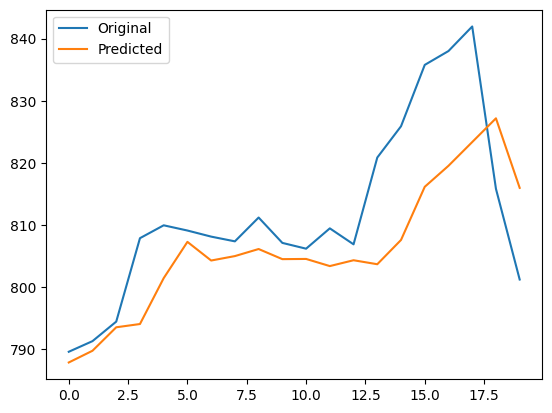

In [42]:
plt.plot(test,label='Original')
plt.plot(pred1,label='Predicted')
plt.legend()
plt.show()

In [48]:
### Input layer and First Hidden layer
lstm = tf.keras.models.Sequential()
lstm.add(tf.keras.layers.LSTM(units=60,return_sequences=True,input_shape=(60,1)))
### Second Hidden Layer
lstm.add(tf.keras.layers.LSTM(units=60,return_sequences=True))
### Third layer
lstm.add(tf.keras.layers.LSTM(units=60,return_sequences=True))
## Forth layer
lstm.add(tf.keras.layers.LSTM(units=60))
### Output Layer
lstm.add(tf.keras.layers.Dense(units=1))

In [54]:
### Model Compile
lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
             loss=tf.keras.losses.mse)

In [55]:
### Model Training
lstm.fit(x_train,y_train,epochs=30,batch_size=40)

Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 122ms/step - loss: 0.0037
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - loss: 0.0014
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 130ms/step - loss: 0.0013
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 123ms/step - loss: 0.0012    
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 173ms/step - loss: 0.0012
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 127ms/step - loss: 0.0013
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 123ms/step - loss: 0.0012
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 178ms/step - loss: 0.0011
Epoch 9/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 123ms/step - loss: 0.0011    
Epoch 10/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 122ms/step - loss: 0.0011
Epoch 11/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 240ms/step - loss: 0.0011
Epoch 12/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 122ms/step - loss: 9.4784e-04
Epoch 13/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 177ms/step - loss: 0.0011
Epoch 14/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 122ms/step - loss: 8.2281e-04
Epoch 15/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 5s

In [56]:
pred = lstm.predict(x_test)
pred1 = min_max.inverse_transform(pred)
pred1

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 535ms/step


array([[773.9023 ],
       [782.4946 ],
       [783.77637],
       [784.1986 ],
       [796.492  ],
       [797.72076],
       [793.9609 ],
       [793.4777 ],
       [794.14154],
       [798.34283],
       [794.1677 ],
       [792.8014 ],
       [797.451  ],
       [795.1085 ],
       [808.0566 ],
       [812.81366],
       [819.2767 ],
       [820.5071 ],
       [823.71387],
       [798.1113 ]], dtype=float32)

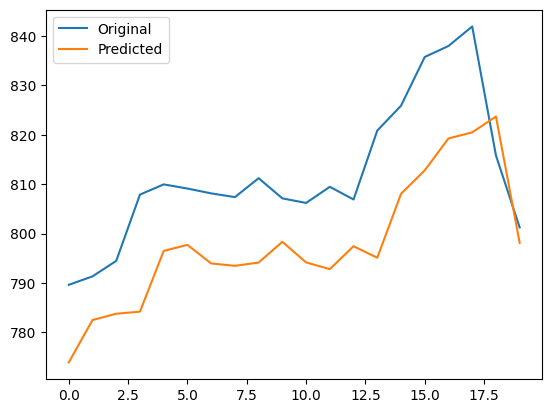

In [57]:
plt.plot(test,label='Original')
plt.plot(pred1,label='Predicted')
plt.legend()
plt.show()

In [58]:
### Input Layer and First Hidden layer
gru = tf.keras.models.Sequential()
gru.add(tf.keras.layers.GRU(units=60,return_sequences=True,input_shape=(60,1)))
## Second Hidden Layer
gru.add(tf.keras.layers.GRU(units=60,return_sequences=True))
## Third Hidden layer
gru.add(tf.keras.layers.GRU(units=60,return_sequences=True))
## Forth Hidden layer
gru.add(tf.keras.layers.GRU(units=60))
## Output Layer
gru.add(tf.keras.layers.Dense(units=1))

In [59]:
## Model Compile
gru.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss=tf.keras.losses.mse)

In [60]:
## Model Training
gru.fit(x_train,y_train,epochs=30,batch_size=40)

Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 14s 211ms/step - loss: 0.0362
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 13s 293ms/step - loss: 0.0020
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 323ms/step - loss: 9.5825e-04
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 228ms/step - loss: 8.2963e-04
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 288ms/step - loss: 7.8013e-04
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 352ms/step - loss: 7.7571e-04
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 224ms/step - loss: 6.6028e-04
Epoch 8/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 12s 288ms/step - loss: 6.2969e-04
Epoch 9/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 148ms/step - loss: 5.7822e-04
Epoch 10/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 211ms/step - loss: 5.4923e-04
Epoch 11/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 9s 156ms/step - loss: 5.4980e-04
Epoch 12/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 199ms/step - loss: 5.0079e-04
Epoch 13/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 4s 146ms/step - loss: 4.8554e-04
Epoch 14/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 6s 186ms/step - loss: 5.0244e-04
Epo

In [61]:
pred = gru.predict(x_test)
pred1 = min_max.inverse_transform(pred)
pred1

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 654ms/step


array([[790.9029 ],
       [795.2108 ],
       [798.2932 ],
       [801.261  ],
       [812.12823],
       [816.93713],
       [816.8221 ],
       [815.6531 ],
       [814.69354],
       [817.36066],
       [815.154  ],
       [813.495  ],
       [815.6653 ],
       [814.5142 ],
       [824.5467 ],
       [831.639  ],
       [840.4284 ],
       [844.2213 ],
       [847.5911 ],
       [828.2156 ]], dtype=float32)

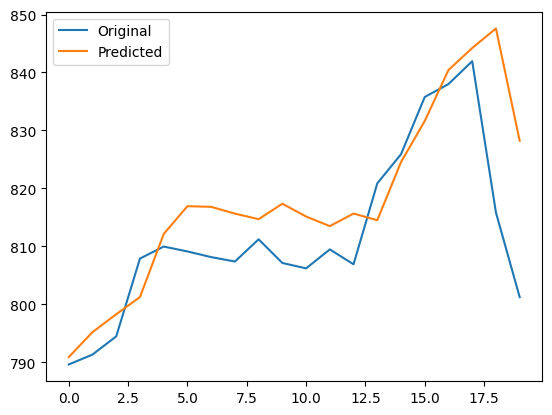

In [62]:
plt.plot(test,label='Original')
plt.plot(pred1,label='Predicted')
plt.legend()
plt.show()